# Selected High- and Low-Relevance Firms, Colored by Sector

| Item | Description |
|---|---|
| Goal | Two figures for the topic relevance score of T3.4.1, each with horizontal bars for named firms at the high end and the low end of the score: the cases selected by the authors (Figure 1) and the marked list (Figure 2). Each bar is the firm's score minus the sample mean; the information sector is highlighted. Figure 2 is Figure 3, Panel B of the proposal. |
| Input | `firm_relevance.parquet` from T3.4.1 in the T3.4 Processed folder. |
| Output | Under `R - Results/figures/...`: `fig_selected_high_and_low_relevance_firms_by_sector` (Figure 1, the cases selected by the authors, 18 firms) and `fig_selected_firms_from_csv_relevance` (Figure 2, the marked list, 22 firms), each as PNG, SVG, and PDF. Under `R - Results/tables/...`: `table_cases_selected_by_authors.csv` and `table_selected_firms_marked_list.csv`, the firms of each figure with their scores, sectors, and ranks. |
| Selection | Both by hand. Cases selected by the authors (Figure 1), among the 60 highest and 60 lowest firms: 14 high-relevance firms (Visa, Nielsen, Alphabet, Verizon, Qualcomm, Cisco, Apple, Allstate, Amazon, Equifax, Microsoft, Mastercard, Oracle, GE HealthCare) and 4 low-relevance firms (Kansas City Southern, Morgan Stanley, Norwegian Cruise Line, Pepsi Bottling Group). Marked list (Figure 2, Milan Miric, 2026-10-31): 33 firms were marked on the score list and the middle cohort from Albertsons to Kraft Foods was dropped, leaving 14 high-relevance firms (Visa to Meta Platforms) and 8 low-relevance firms (Brown-Forman to Pep Boys). Both lists are named by gvkey in Step 2. |
| Style | S3 layout: a BLACK zero line, the legend below the X-title, no text inside the plot. The two bar colours are those of the proposal's Panel B: CRIMSON for information-sector firms and DARK_SLATE for the other sectors. |
| Run | Run 2026-11-01. Figure 1 is unchanged from its first run of 2026-10-31; Figure 2 reproduces the figure Milan Miric added on 2026-10-31 and placed in the proposal as Panel B. |


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.patches import Patch


## Step 2. Define file locations, the selected firms, and the wording


In [2]:
PROJECT_FOLDER = Path.cwd().resolve().parents[2]  # <pipeline>/<section>/<subfolder>/ sits three levels below the clone
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis")  # the one line to change on another machine
NOTEBOOK_SUBFOLDER = Path("T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure/T3.4 - Topic Relevance - Score and Figures")
NOTEBOOK_NAME = "T3.4.4 - Figure - Selected High and Low Relevance Firms"  # the notebook filename without .ipynb
RAW_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Raw"
INTERIM_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Interim"
PROCESSED_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Processed"
SCORES_FILE = PROCESSED_FOLDER / "firm_relevance.parquet"

SAMPLE = "all_years"
SELECTED_FIRMS = {  # Figure 1, the cases selected by the authors: gvkey -> end of the distribution
    "179534": "highest",  # Visa
    "100873": "highest",  # Nielsen
    "160329": "highest",  # Alphabet
    "002136": "highest",  # Verizon
    "024800": "highest",  # Qualcomm
    "020779": "highest",  # Cisco
    "001690": "highest",  # Apple
    "028349": "highest",  # Allstate
    "064768": "highest",  # Amazon
    "004423": "highest",  # Equifax
    "012141": "highest",  # Microsoft
    "160225": "highest",  # Mastercard
    "012142": "highest",  # Oracle
    "041818": "highest",  # GE HealthCare
    "006335": "lowest",  # Kansas City Southern
    "012124": "lowest",  # Morgan Stanley
    "104432": "lowest",  # Norwegian Cruise Line
    "119417": "lowest",  # Pepsi Bottling Group
}
MARKED_SELECTION = {  # Figure 2, the marked list: gvkey -> (end of the distribution, display name); 33 firms marked on 2026-10-31, the middle cohort dropped
    "179534": ("highest", "Visa Inc."),
    "100873": ("highest", "Nielsen Holdings"),
    "160329": ("highest", "Alphabet Inc."),
    "186106": ("highest", "Motorola Mobility"),
    "014438": ("highest", "ADT Corp."),
    "035182": ("highest", "CrowdStrike Holdings"),
    "171067": ("highest", "Palo Alto Networks"),
    "020779": ("highest", "Cisco Systems"),
    "001690": ("highest", "Apple Inc."),
    "064768": ("highest", "Amazon.com Inc."),
    "160225": ("highest", "Mastercard Inc."),
    "012142": ("highest", "Oracle Corp."),
    "157855": ("highest", "Salesforce Inc."),
    "170617": ("highest", "Meta Platforms"),
    "002435": ("lowest", "Brown-Forman Corp."),
    "001663": ("lowest", "Anheuser-Busch Cos."),
    "003505": ("lowest", "Molson Coors Beverage Co."),
    "007017": ("lowest", "Marathon Oil Corp."),
    "012124": ("lowest", "Morgan Stanley"),
    "104432": ("lowest", "Norwegian Cruise Line"),
    "119417": ("lowest", "Pepsi Bottling Group"),
    "008475": ("lowest", "Pep Boys (Manny Moe & Jack)"),
}
HIGHLIGHT_SECTOR = "Information"
FIRM_SUMMARY_TITLE = "a Firm-Level Summary of 10-K Item 1s"
POLICY_SUMMARY_TITLE = "the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation"
SCORE_TITLE = f"Cosine Similarity Between {FIRM_SUMMARY_TITLE} and {POLICY_SUMMARY_TITLE}"
SCORE_WORDS = ("the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's "
               "yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the "
               "language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. "
               "A higher score means that the firm's business description is closer to the policy summary")
SAMPLE_WORDS = {"three_years": "the three-year sample (fiscal years 2010, 2015, and 2020)", "all_years": "the all-years sample (every fiscal year a firm filed, 1999 to 2025)"}
SOURCE = "10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations"
FIGURE_NAMES = {1: "fig_selected_high_and_low_relevance_firms_by_sector", 2: "fig_selected_firms_from_csv_relevance"}
FIGURE_TITLES = {1: f"Cases Selected by the Authors: High- and Low-Relevance Firms on {SCORE_TITLE}, Minus the Sample Mean",
                 2: f"Marked List: High- and Low-Relevance Firms on {SCORE_TITLE}, Minus the Sample Mean"}
X_TITLE = "Cosine Similarity to Policy Summary, Minus Sample Mean"
FIGURE_FOLDER = PROJECT_FOLDER / "R - Results/figures" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
TABLE_FOLDER = PROJECT_FOLDER / "R - Results/tables" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
MODEL_CACHE = SCRATCH_FOLDER / "cache" / "huggingface"
ENV_FILE = PROJECT_FOLDER / "T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure" / ".env"
for folder in (FIGURE_FOLDER, TABLE_FOLDER):
    folder.mkdir(parents=True, exist_ok=True)


## Step 3. Apply the figure style


In [3]:
# Colors from the Figure Style Guide
BLACK = "#000000"
DODGER_BLUE = "#1E90FF"
SLATE_GREY = "#708090"
CRIMSON = "#B31942"  # the proposal's Panel B colours, kept for this figure
DARK_SLATE = "#5A6B7C"
CYAN = "#00ACC1"
GREY = "#A6A6A8"

# Font and background
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True

# Horizontal background lines only
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5

# All text and axis lines in BLACK
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK

FIGURE_WIDTH, FIGURE_HEIGHT = 9, 6
MARGIN_INCHES = 0.5 / 2.54  # 0.5 cm between each edge of the image and the nearest element
ZERO_LINE_WIDTH = 0.8 / 3
EXPORT_DPI = 300
BAR_HEIGHT = 0.75
FIRM_LABEL_SIZE = 8.5


def fit_margins(figure, axis):
    """Move the axes so the Y-title starts 0.5 cm from the left edge, the X-title ends 0.5 cm above the bottom edge, and nothing crosses the right or top margin."""
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    margin = MARGIN_INCHES * figure.dpi
    left_shift = (margin - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
    figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
    figure.canvas.draw()
    bottom_shift = (margin - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
    figure.canvas.draw()
    box = axis.get_tightbbox(renderer)
    right_over = box.x1 - (figure.bbox.width - margin)
    top_over = box.y1 - (figure.bbox.height - margin)
    if right_over > 0 or top_over > 0:
        figure.subplots_adjust(right=figure.subplotpars.right - max(right_over, 0) / figure.bbox.width,
                               top=figure.subplotpars.top - max(top_over, 0) / figure.bbox.height)
        figure.canvas.draw()
    return renderer


def legend_below(figure, axis, handles, labels, ncol=1, fontsize=10):
    """Place the legend with its top 0.5 cm below the X-title and its bottom 0.5 cm above the bottom edge; the bottom margin grows to make room."""
    renderer = fit_margins(figure, axis)
    margin = MARGIN_INCHES * figure.dpi
    axis_box = axis.get_window_extent(renderer)
    center = (axis_box.x0 + axis_box.x1) / 2 / figure.bbox.width
    x_title = axis.xaxis.label.get_window_extent(renderer)
    legend = figure.legend(handles, labels, loc="upper center", bbox_to_anchor=(center, (x_title.y0 - margin) / figure.bbox.height),
                           bbox_transform=figure.transFigure, ncol=ncol, frameon=False, handlelength=1.6, fontsize=fontsize)
    figure.canvas.draw()
    bottom_shift = (margin - legend.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
    figure.canvas.draw()
    x_title = axis.xaxis.label.get_window_extent(renderer)
    legend.set_bbox_to_anchor((center, (x_title.y0 - margin) / figure.bbox.height), transform=figure.transFigure)
    figure.canvas.draw()
    return legend


def save_figure(figure, stem):
    """Export PNG, SVG, and PDF into the notebook's figure folder."""
    FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)
    for extension in ("png", "svg", "pdf"):
        figure.savefig(FIGURE_FOLDER / f"{stem}.{extension}", dpi=EXPORT_DPI if extension == "png" else None)
    plt.close(figure)
    print(f"saved {stem}.png/.svg/.pdf")


def show_figure(number, title, stem, notes, source):
    """Title, image, Notes, and Source, in that order, as Markdown outside the image."""
    display(Markdown(f"**Figure {number}. {title}**"))
    display(Image(filename=str(FIGURE_FOLDER / f"{stem}.png"), width=900))
    display(Markdown(f"*Notes*: {notes}"))
    display(Markdown(f"*Source*: {source}."))


## Step 4. Load the scores, demean them, and pick the two sets of firms

Every selected gvkey must be in the sample, the high group above the sample mean and the low group below it. Figure 1 shows Compustat names in title case with the common suffixes kept short; Figure 2 uses the display names its selection recorded. Each selection is saved as a table.


In [4]:
scores = pd.read_parquet(SCORES_FILE)
scores = scores.loc[scores["sample"].eq(SAMPLE)].reset_index(drop=True)
sample_mean = float(scores["score"].mean())
scores["demeaned"] = scores["score"] - sample_mean
scores["rank"] = scores["score"].rank(ascending=False, method="min").astype(int)
scores["display_name"] = scores["conm"].str.title().str.replace(r"\s+-Cl\s+\w+$", "", regex=True).str.replace(r"Inc$", "Inc.", regex=True).str.replace(r"Corp$", "Corp.", regex=True)
columns = ["end", "gvkey", "conm", "display_name", "naics", "naics2", "sector", "score", "demeaned", "rank"]

assert set(SELECTED_FIRMS) <= set(scores["gvkey"]), sorted(set(SELECTED_FIRMS) - set(scores["gvkey"]))
selected = scores.loc[scores["gvkey"].isin(SELECTED_FIRMS)].copy()
selected["end"] = selected["gvkey"].map(SELECTED_FIRMS)
selected = selected.sort_values("score", ascending=False).reset_index(drop=True)
assert selected.loc[selected["end"].eq("highest"), "rank"].le(60).all() and selected.loc[selected["end"].eq("lowest"), "rank"].gt(len(scores) - 60).all()
selected[columns].to_csv(TABLE_FOLDER / "table_cases_selected_by_authors.csv", index=False, float_format="%.6f")

assert set(MARKED_SELECTION) <= set(scores["gvkey"]), sorted(set(MARKED_SELECTION) - set(scores["gvkey"]))
marked = scores.loc[scores["gvkey"].isin(MARKED_SELECTION)].copy()
marked["end"] = marked["gvkey"].map(lambda g: MARKED_SELECTION[g][0])
marked["display_name"] = marked["gvkey"].map(lambda g: MARKED_SELECTION[g][1])
marked = marked.sort_values("score", ascending=False).reset_index(drop=True)
assert marked.loc[marked["end"].eq("highest"), "demeaned"].gt(0).all() and marked.loc[marked["end"].eq("lowest"), "demeaned"].lt(0).all()
marked[columns].to_csv(TABLE_FOLDER / "table_selected_firms_marked_list.csv", index=False, float_format="%.6f")
print(f"Sample mean over {len(scores):,} firms: {sample_mean:.4f}")
print(f"Figure 1: {int(selected['end'].eq('highest').sum())} high and {int(selected['end'].eq('lowest').sum())} low firms; Figure 2: {int(marked['end'].eq('highest').sum())} high and {int(marked['end'].eq('lowest').sum())} low firms")
display(pd.concat([selected[["display_name", "sector", "score", "rank"]].reset_index(drop=True), marked[["display_name", "sector", "score", "rank"]].reset_index(drop=True)], axis=1, keys=["Cases selected by the authors", "Marked list"]))


Sample mean over 1,058 firms: 0.5121
Figure 1: 14 high and 4 low firms; Figure 2: 14 high and 8 low firms


Cases selected by the authors  \
                     display_name   
0                       Visa Inc.   
1            Nielsen Holdings Plc   
2                   Alphabet Inc.   
3     Verizon Communications Inc.   
4                   Qualcomm Inc.   
5              Cisco Systems Inc.   
6                      Apple Inc.   
7                  Allstate Corp.   
8                 Amazon.Com Inc.   
9                    Equifax Inc.   
10                Microsoft Corp.   
11                Mastercard Inc.   
12                   Oracle Corp.   
13  Ge Healthcare Technologi Inc.   
14           Kansas City Southern   
15                 Morgan Stanley   
16    Norwegian Cruise Line Hldgs   
17      Pepsi Bottling Group Inc.   
18                            NaN   
19                            NaN   
20                            NaN   
21                            NaN   

                                                                        \
                                              sector     score    rank   
0                              Finance and insurance  0.620883     1.0   
1   Professional, scientific, and technical services  0.613060     5.0   
2                                        Information  0.609440     8.0   
3                                        Information  0.607030     9.0   
4                                      Manufacturing  0.600682    13.0   
5                                      Manufacturing  0.595573    18.0   
6                                      Manufacturing  0.594128    19.0   
7                              Finance and insurance  0.591812    20.0   
8                                       Retail trade  0.591493    21.0   
9    Administrative and support and waste management  0.591470    22.0   
10                                       Information  0.589822    23.0   
11                             Finance and insurance  0.581390    36.0   
12                                       Information  0.578639    41.0   
13                                     Manufacturing  0.575430    49.0   
14                    Transportation and warehousing  0.445154  1037.0   
15                             Finance and insurance  0.443511  1041.0   
16                    Transportation and warehousing  0.437907  1047.0   
17                                     Manufacturing  0.429339  1051.0   
18                                               NaN       NaN     NaN   
19                                               NaN       NaN     NaN   
20                                               NaN       NaN     NaN   
21                                               NaN       NaN     NaN   

                    Marked list  \
                   display_name   
0                     Visa Inc.   
1              Nielsen Holdings   
2                 Alphabet Inc.   
3             Motorola Mobility   
4                     ADT Corp.   
5          CrowdStrike Holdings   
6            Palo Alto Networks   
7                 Cisco Systems   
8                    Apple Inc.   
9               Amazon.com Inc.   
10              Mastercard Inc.   
11                 Oracle Corp.   
12              Salesforce Inc.   
13               Meta Platforms   
14           Brown-Forman Corp.   
15          Anheuser-Busch Cos.   
16    Molson Coors Beverage Co.   
17           Marathon Oil Corp.   
18               Morgan Stanley   
19        Norwegian Cruise Line   
20         Pepsi Bottling Group   
21  Pep Boys (Manny Moe & Jack)   

                                                                      
                                              sector     score  rank  
0                              Finance and insurance  0.620883     1  
1   Professional, scientific, and technical services  0.613060     5  
2                                        Information  0.609440     8  
3                                      Manufacturing  0.606267    10  
4    Administrative and support and waste management  0.602478    11  


## Step 5. Define the drawing

One bar per firm from zero, the sample mean, to the firm's demeaned score; the high firms above a gap, the low firms below; the information sector in CRIMSON, the other sectors in DARK_SLATE; the legend below the X-title.


In [5]:
def draw_selection(frame, stem):
    """Draw one selection, highest score at the top, a gap between the high and the low group, and save it under stem."""
    high = frame.loc[frame["end"].eq("highest")].reset_index(drop=True)
    low = frame.loc[frame["end"].eq("lowest")].reset_index(drop=True)
    labels = high["display_name"].tolist() + [""] + low["display_name"].tolist()
    positions = np.arange(len(labels))[::-1]
    color_of = lambda sector: CRIMSON if sector == HIGHLIGHT_SECTOR else DARK_SLATE
    reach = float(frame["demeaned"].abs().max()) * 1.15
    figure, axis = plt.subplots()
    figure.subplots_adjust(left=0.28, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.2)
    axis.barh(positions[:len(high)], high["demeaned"], color=[color_of(s) for s in high["sector"]], height=BAR_HEIGHT, zorder=2)
    axis.barh(positions[len(high) + 1:], low["demeaned"], color=[color_of(s) for s in low["sector"]], height=BAR_HEIGHT, zorder=2)
    axis.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=3)
    axis.set_yticks(positions, labels=labels)
    axis.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
    axis.set_xlim(-reach, reach)
    axis.set_xlabel(X_TITLE)
    axis.set_ylabel("Sample Firm")
    axis.tick_params(axis="y", length=0, labelsize=FIRM_LABEL_SIZE)
    axis.spines[["top", "right"]].set_visible(False)
    legend_below(figure, axis, [Patch(facecolor=CRIMSON), Patch(facecolor=DARK_SLATE)], [f"{HIGHLIGHT_SECTOR} Sector (NAICS 51)", "Other Sectors"], ncol=2)
    save_figure(figure, stem)
    return len(high), len(low)


## Step 6. Figure 1: the cases selected by the authors

The 18 firms the authors chose among the 60 highest and 60 lowest scores.


In [6]:
n_high, n_low = draw_selection(selected, FIGURE_NAMES[1])
notes_1 = (f"Each bar is the firm's score minus the sample mean, {sample_mean:.3f}, over all {len(scores):,} firms of {SAMPLE_WORDS[SAMPLE]}; zero is the sample mean. "
           f"The {n_high} firms above the gap are cases the authors selected among the 60 highest scores and the {n_low} firms below it among the 60 lowest, as well-known names; "
           f"within each group, firms are ordered from the highest score at the top. Red bars are firms of the information sector (NAICS 51); grey bars are firms of other sectors. The score is {SCORE_WORDS}.")


saved fig_selected_high_and_low_relevance_firms_by_sector.png/.svg/.pdf


## Step 7. Figure 2: the marked list

The 22 firms that remain of a list of 33 marked on the score list after the middle cohort is dropped; the proposal's Panel B.


In [7]:
n_high, n_low = draw_selection(marked, FIGURE_NAMES[2])
notes_2 = (f"Each bar is the firm's score minus the sample mean, {sample_mean:.3f}, over all {len(scores):,} firms of {SAMPLE_WORDS[SAMPLE]}; zero is the sample mean. "
           f"The {n_high} firms above the gap and the {n_low} firms below it were chosen by hand as well-known names: 33 firms were marked on the score list and the middle cohort, from Albertsons to Kraft Foods, was dropped; "
           f"within each group, firms are ordered from the highest score at the top. Red bars are firms of the information sector (NAICS 51); grey bars are firms of other sectors. The score is {SCORE_WORDS}.")


saved fig_selected_firms_from_csv_relevance.png/.svg/.pdf


## Step 8. Show the figures

Title, image, Notes, and Source for each figure, in that order.


**Figure 1. Cases Selected by the Authors: High- and Low-Relevance Firms on Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, Minus the Sample Mean**

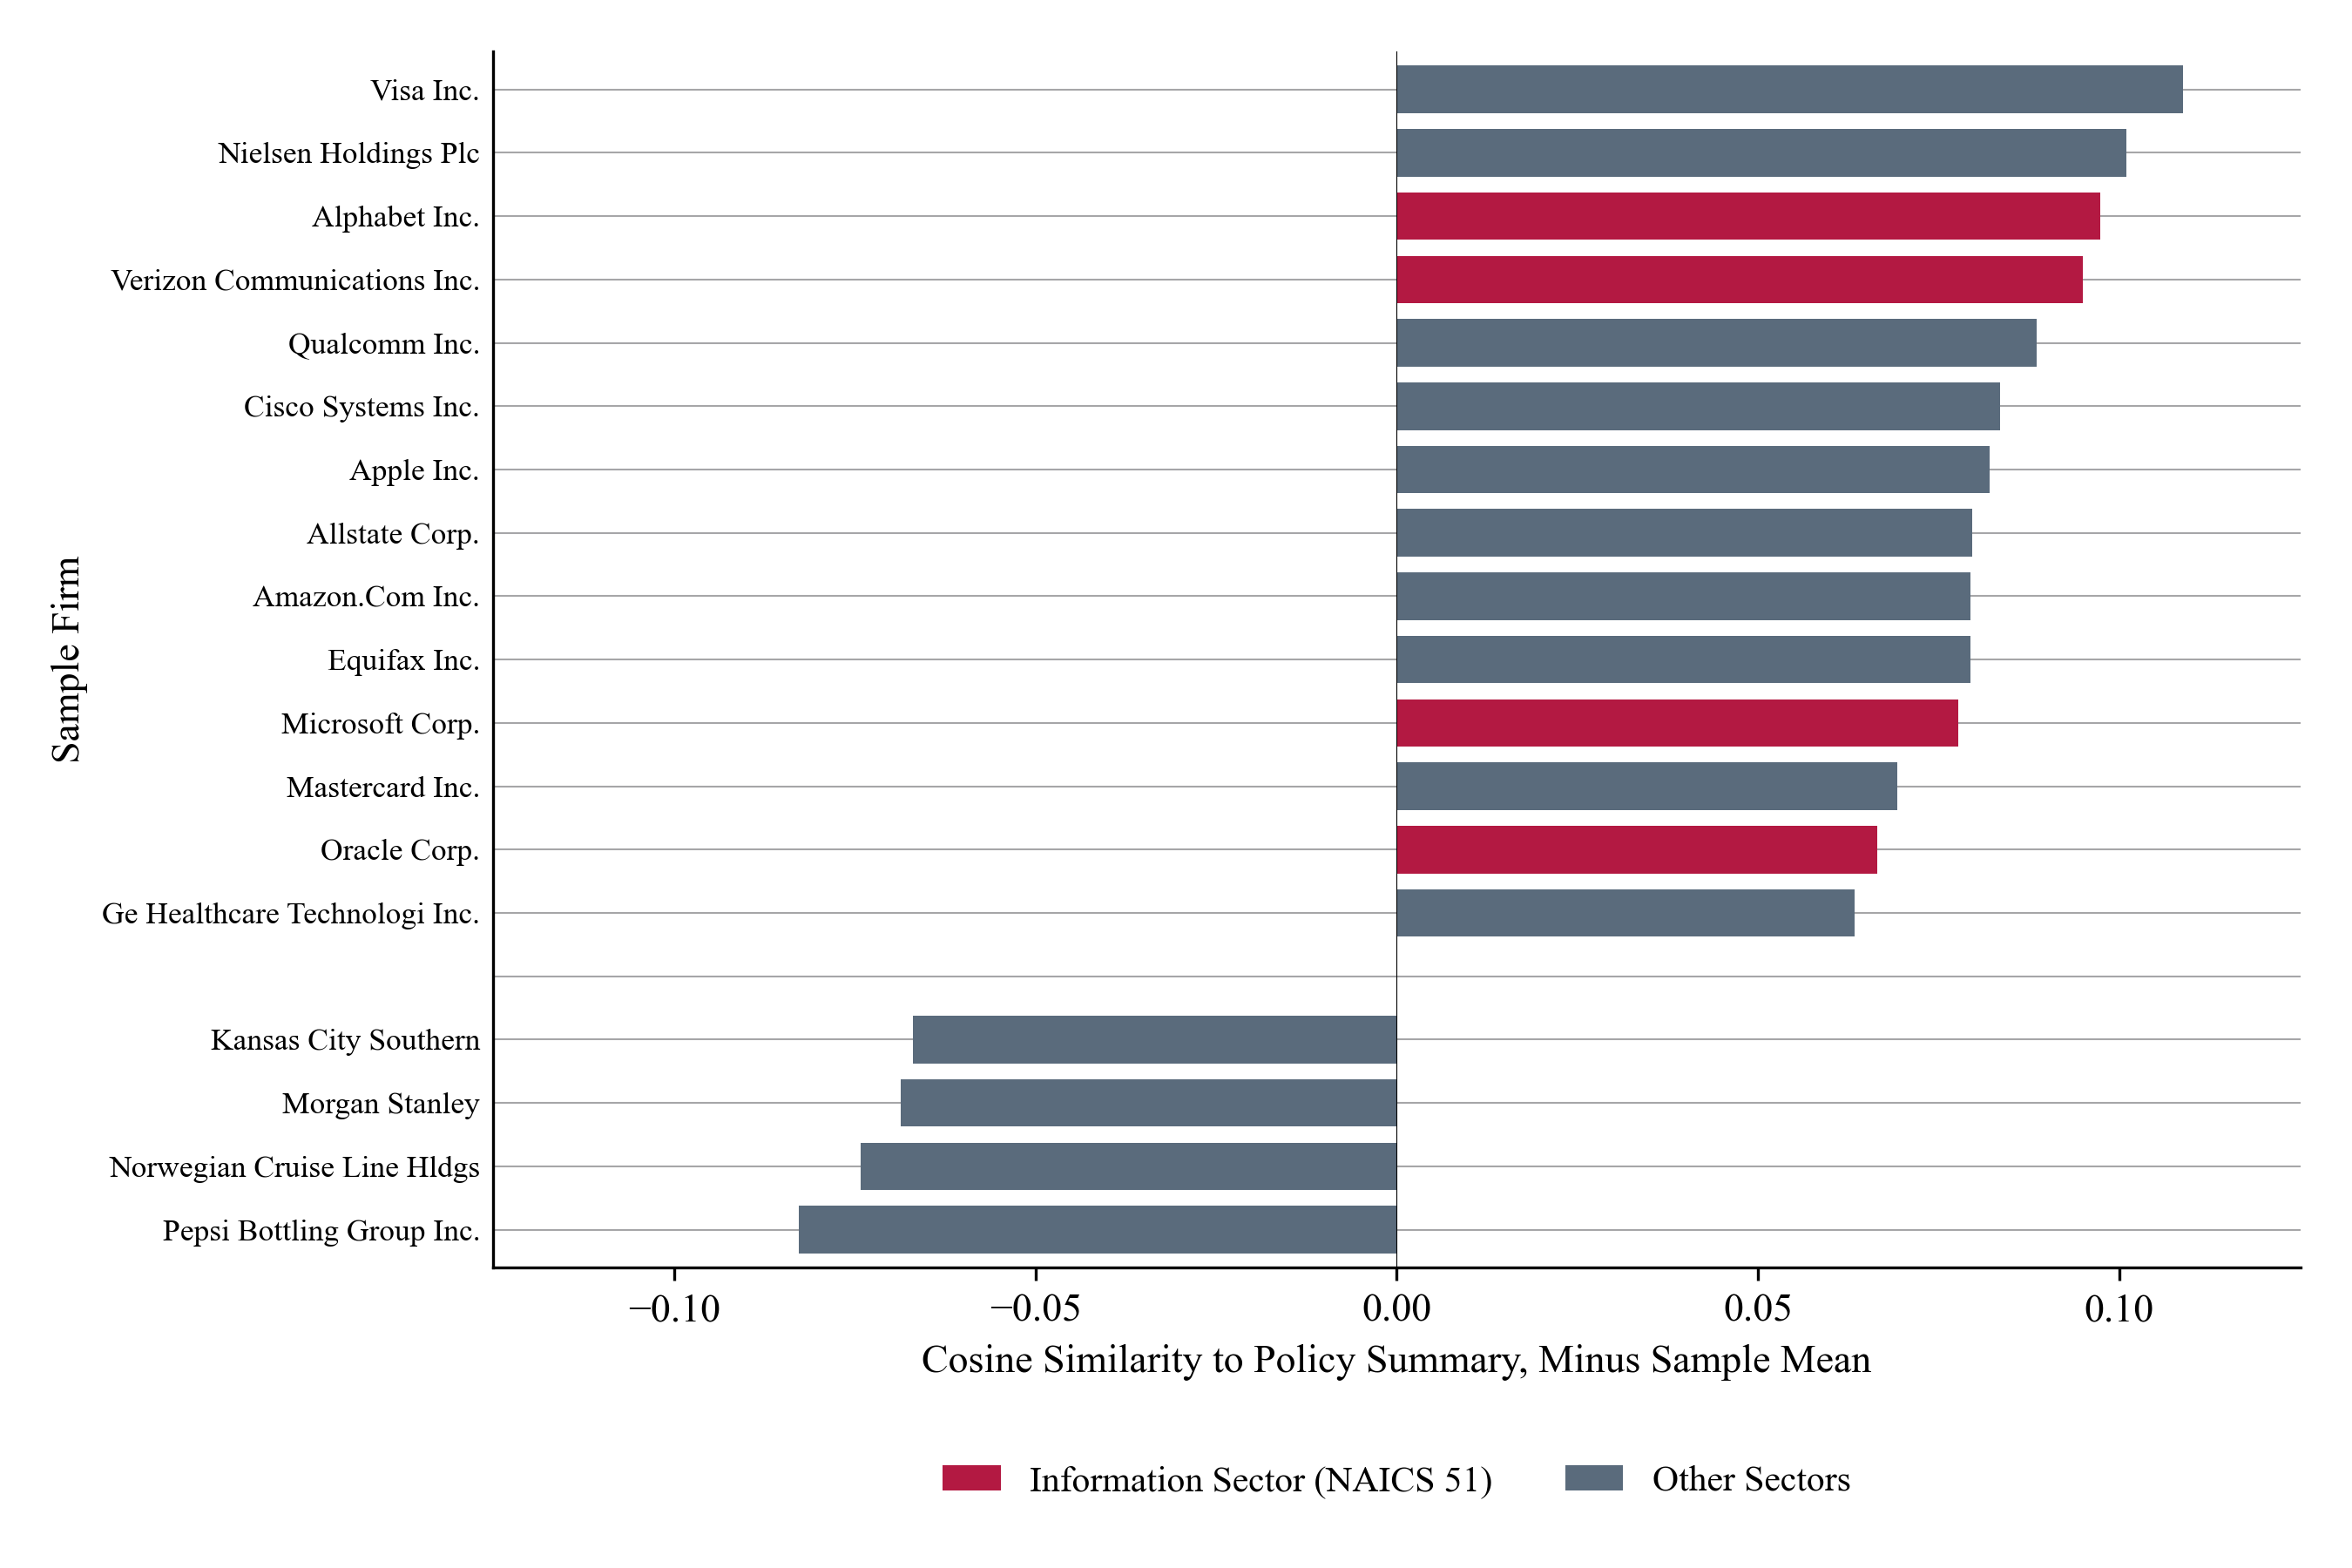

*Notes*: Each bar is the firm's score minus the sample mean, 0.512, over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025); zero is the sample mean. The 14 firms above the gap are cases the authors selected among the 60 highest scores and the 4 firms below it among the 60 lowest, as well-known names; within each group, firms are ordered from the highest score at the top. Red bars are firms of the information sector (NAICS 51); grey bars are firms of other sectors. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 2. Marked List: High- and Low-Relevance Firms on Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, Minus the Sample Mean**

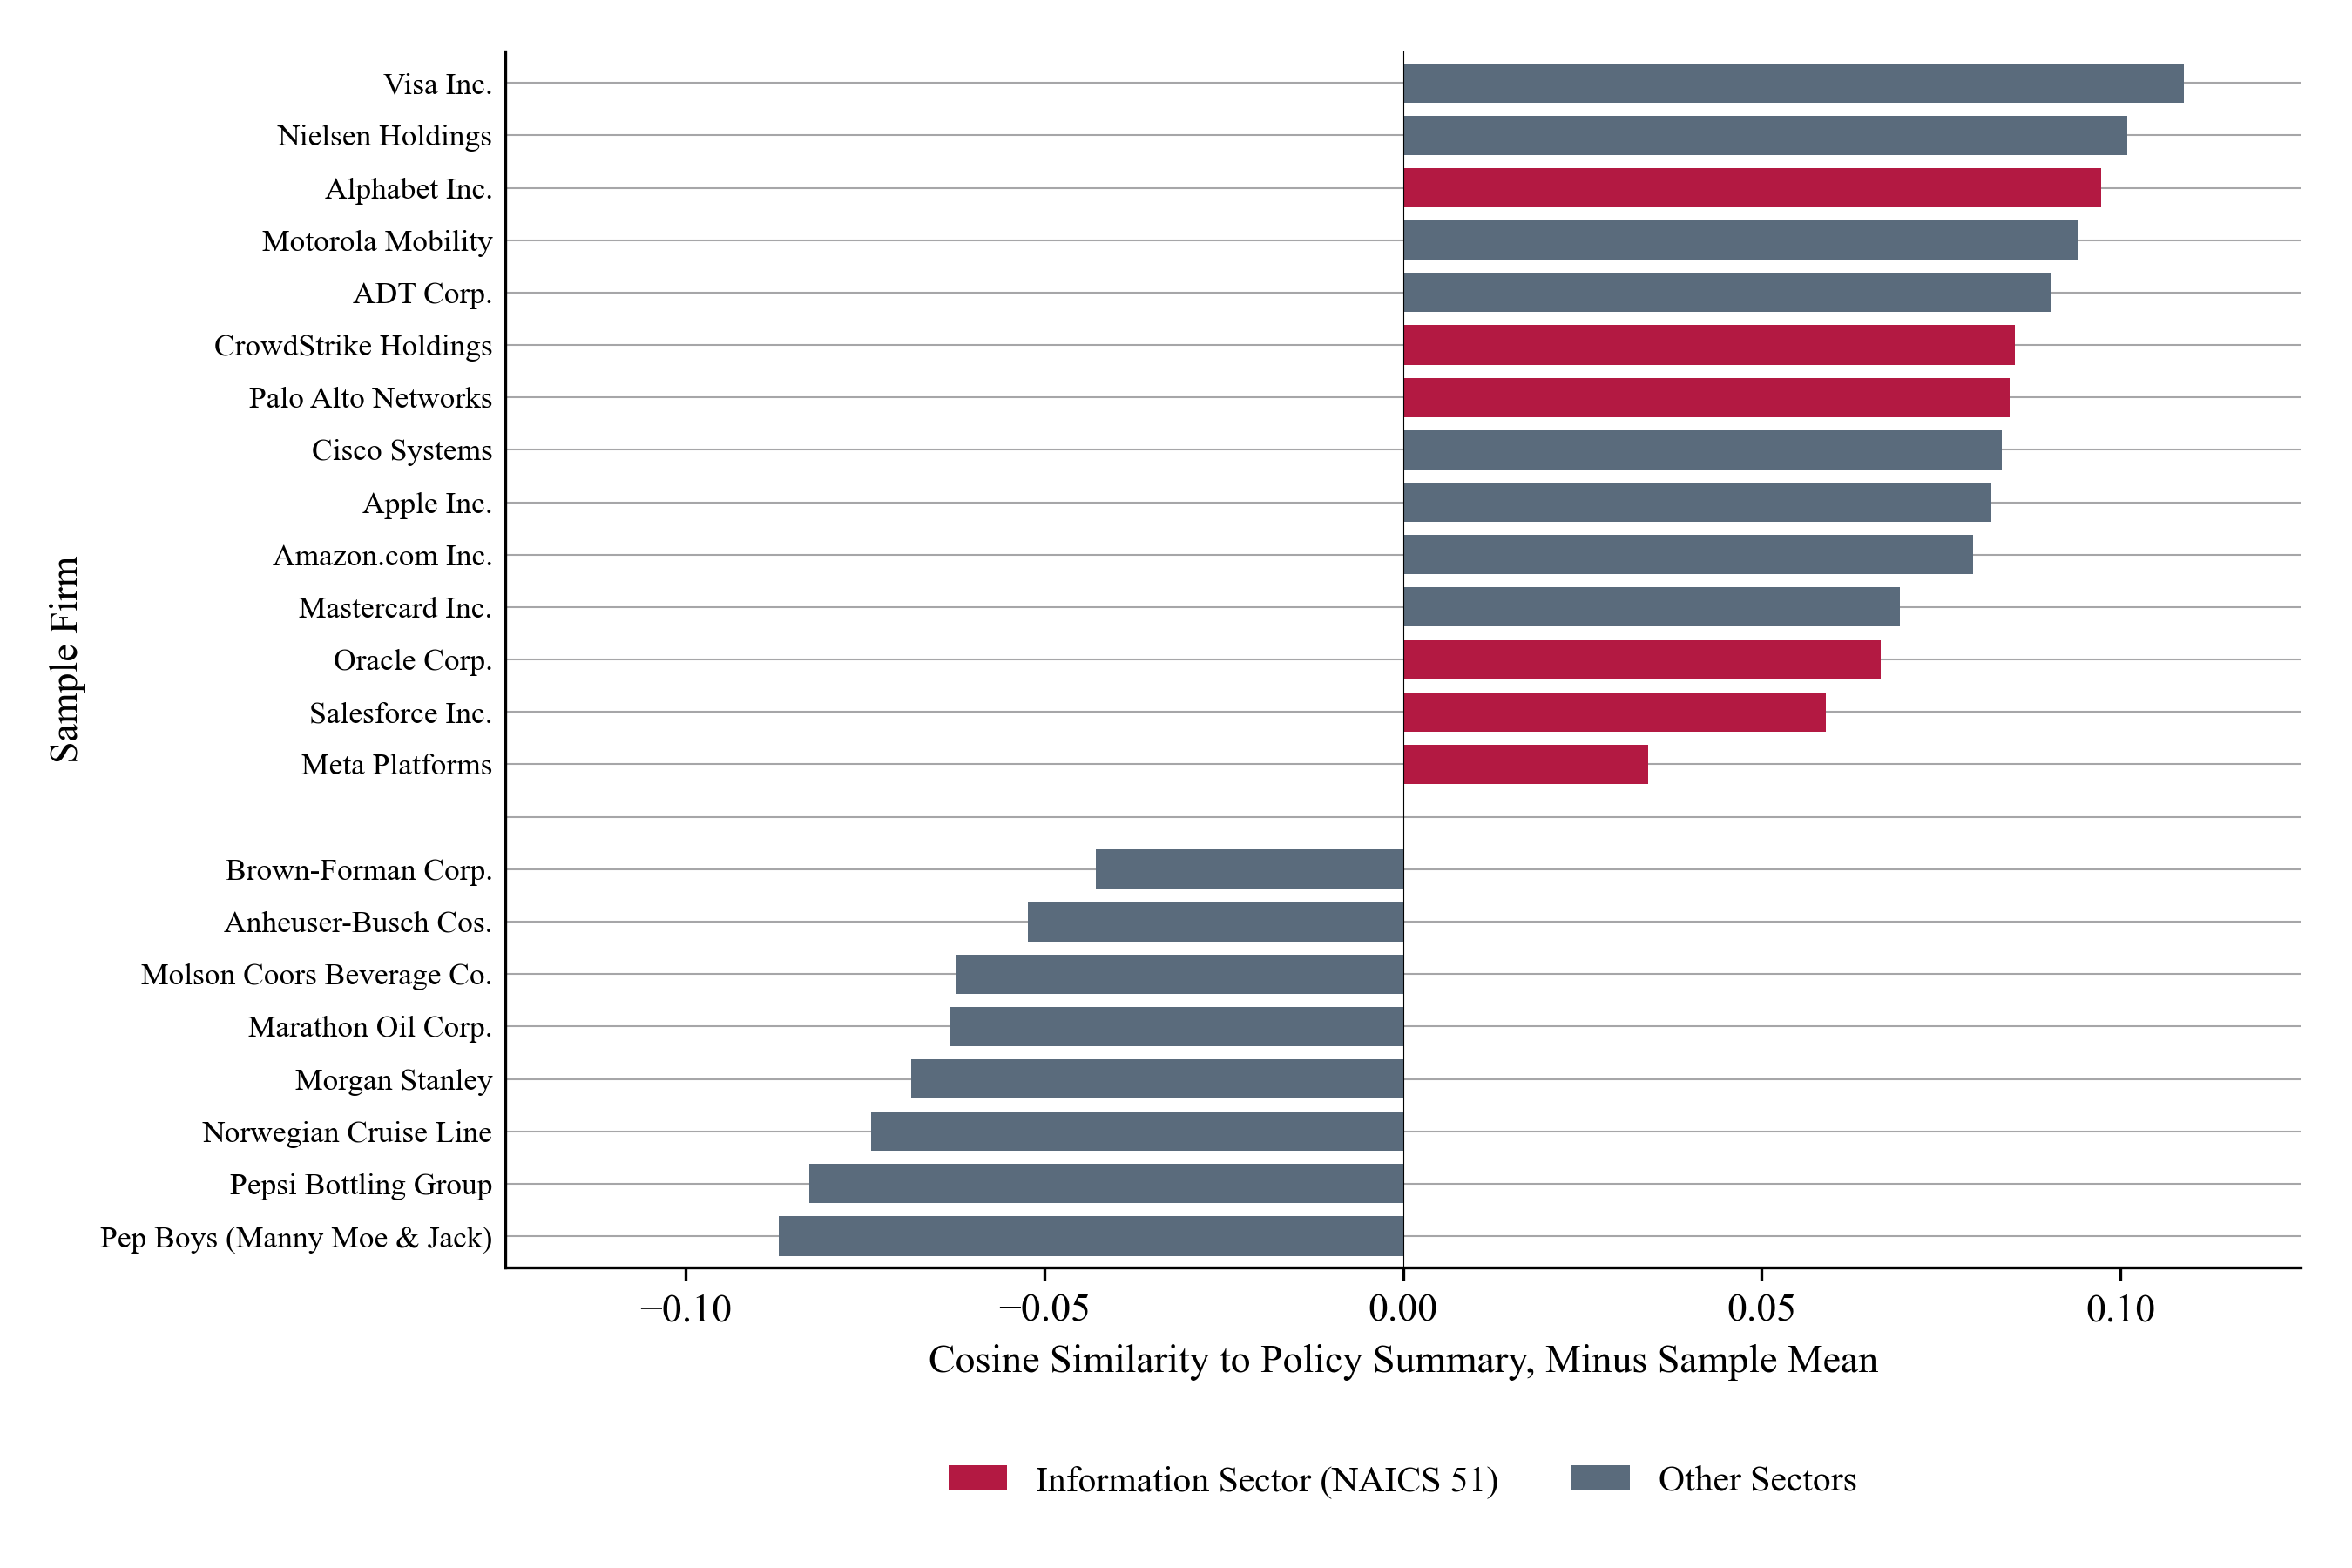

*Notes*: Each bar is the firm's score minus the sample mean, 0.512, over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025); zero is the sample mean. The 14 firms above the gap and the 8 firms below it were chosen by hand as well-known names: 33 firms were marked on the score list and the middle cohort, from Albertsons to Kraft Foods, was dropped; within each group, firms are ordered from the highest score at the top. Red bars are firms of the information sector (NAICS 51); grey bars are firms of other sectors. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [8]:
show_figure(1, FIGURE_TITLES[1], FIGURE_NAMES[1], notes_1, SOURCE)
show_figure(2, FIGURE_TITLES[2], FIGURE_NAMES[2], notes_2, SOURCE)
